<a href="https://colab.research.google.com/github/Nivetha-B93/Clustering-and-Dimensionality-Reduction/blob/main/Clustering_and_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

## Loading the dataset

In [ ]:
df=pd.read_excel("https://github.com/Nivetha-B93/data-sets/raw/refs/heads/main/mall_customer_spend.xlsx")
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Checking the shape, columns, data types, and missing values

In [ ]:
df.shape

(200, 5)

In [ ]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [ ]:
df.dtypes

,0
CustomerID,int64
Genre,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [ ]:
df.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


# **Selecting relevant features for clustering**

We should exclude CustomerID because it is simply an identifier.Genre
is a categorical variable. We could encode it numerically and include it in clustering, but that would make gender influence the distance calculations.
For our initial customer segmentation, let's focus on age, annual income, and spending score.

In [ ]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

X = df[features].copy()

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## **Scaling the numerical features**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

A negative scaled value does not mean that a customer has negative income or a negative spending score. It means the original value is below the feature's mean

In [ ]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled_df.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## **Task 2 – K-Means Clustering**

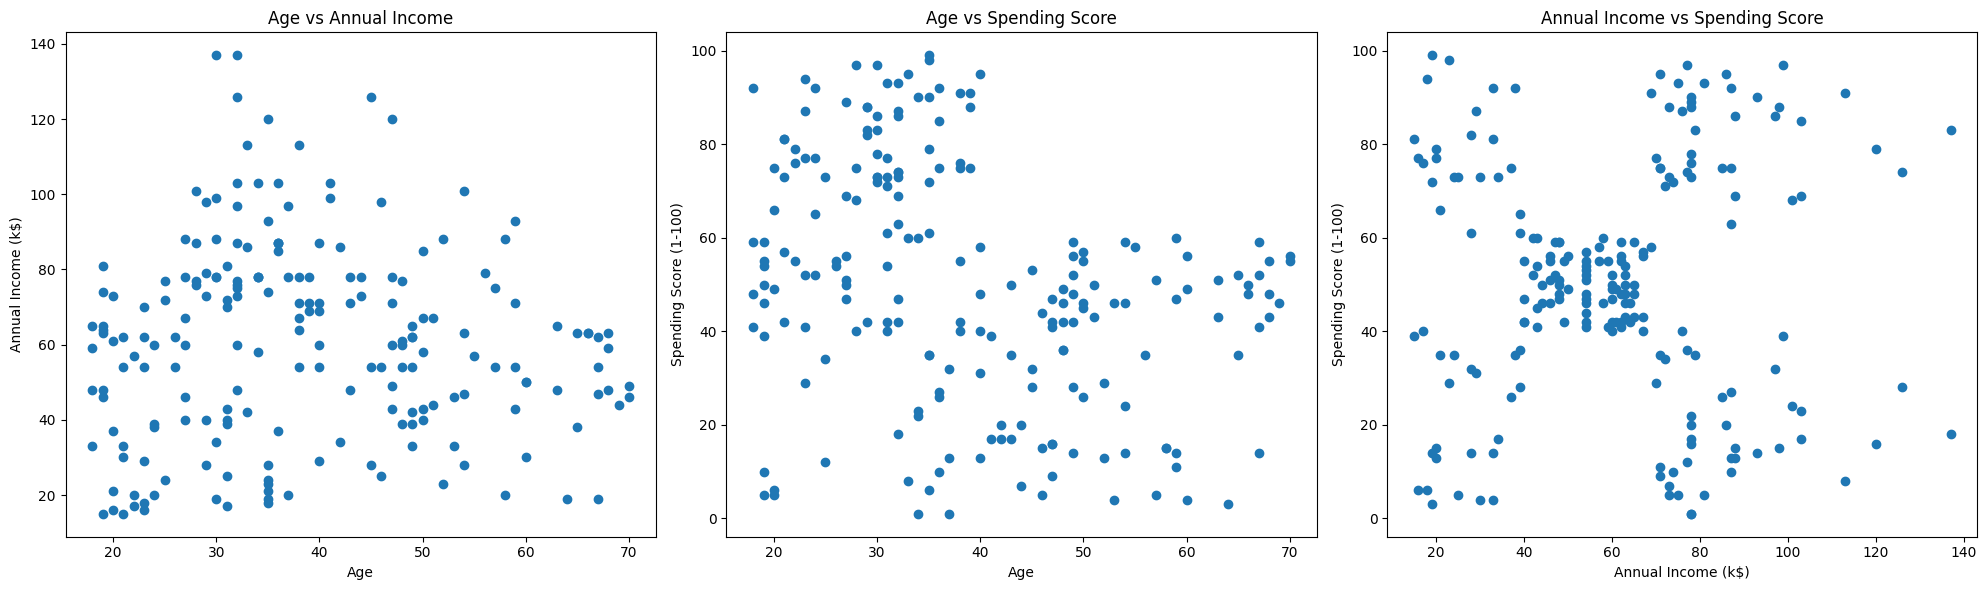

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Age vs Annual Income
axes[0].scatter(df['Age'], df['Annual Income (k$)'])
axes[0].set_title("Age vs Annual Income")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Annual Income (k$)")

# Plot 2: Age vs Spending Score
axes[1].scatter(df['Age'], df['Spending Score (1-100)'])
axes[1].set_title("Age vs Spending Score")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score (1-100)")

# Plot 3: Annual Income vs Spending Score
axes[2].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
axes[2].set_title("Annual Income vs Spending Score")
axes[2].set_xlabel("Annual Income (k$)")
axes[2].set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

## Creating a K-Means model

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)

kmeans.fit(X_scaled_df)

KMeans(n_clusters=5, random_state=42)

# **Predicting cluster labels**

In [ ]:
labels = kmeans.predict(X_scaled_df)

labels

array([2, 2, 3, 2, 2, 2, 3, 2, 0, 2, 0, 2, 0, 2, 3, 2, 3, 2, 0, 2, 3, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 3, 2, 0, 2, 0, 2,
       0, 2, 0, 3, 3, 3, 0, 2, 3, 0, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 0, 3,
       0, 0, 3, 3, 0, 0, 0, 0, 0, 3, 0, 3, 3, 0, 0, 3, 0, 0, 3, 0, 0, 3,
       3, 0, 0, 3, 0, 3, 3, 3, 0, 3, 0, 3, 3, 0, 0, 3, 0, 3, 0, 0, 0, 0,
       0, 3, 3, 3, 3, 3, 0, 0, 0, 0, 3, 3, 1, 1, 3, 1, 4, 1, 4, 1, 4, 1,
       3, 1, 3, 1, 4, 1, 3, 1, 4, 1, 3, 1, 3, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 3, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1], dtype=int32)

In [ ]:
df['Cluster'] = labels

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,3
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


## **Demonstrating the Random Initialization Trap**
Before K-Means starts clustering, it selects initial cluster centres called centroids.

The positions of these initial centroids can affect the final clustering result.

Imagine that you want to divide customers into five groups.

If the initial centroids are well positioned, K-Means may find a good grouping.

However, if the initial centroids are poorly positioned, K-Means may converge to a less effective solution.

This is called the Random Initialization Trap

In [ ]:
for seed in [10, 25, 50]:

    model = KMeans(
        n_clusters=5,
        init='random',
        n_init=1,
        random_state=seed
    )

    model.fit(X_scaled_df)

    print(f"Random state {seed}: Inertia = {model.inertia_:.4f}")

Random state 10: Inertia = 168.7415
Random state 25: Inertia = 168.2476
Random state 50: Inertia = 168.7469


## **Use the Elbow Method to determine the optimal number of clusters**

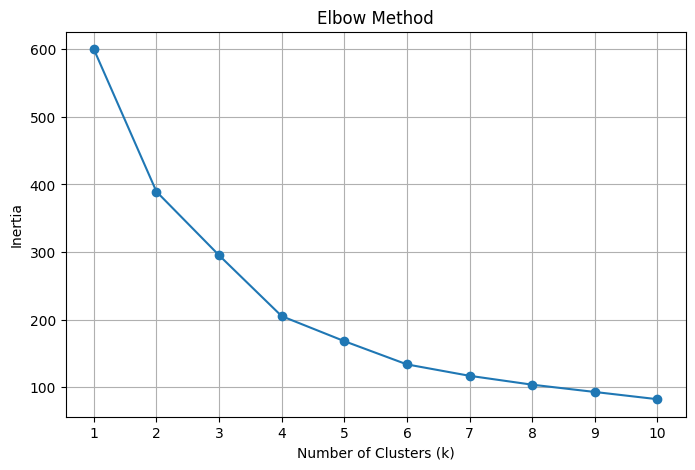

In [ ]:
inertia_values = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled_df)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# The curve begins to bend around k = 4, making four clusters a reasonable choice

# Building our final K-Means model

In [ ]:
from sklearn.cluster import KMeans

# Create the final K-Means model
final_kmeans = KMeans(
    n_clusters=4,
    init='k-means++',
    n_init=10,
    random_state=42
)

# Train the model
final_kmeans.fit(X_scaled_df)

# Assign cluster labels
df['Cluster'] = final_kmeans.labels_

# Display the results
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


# **Check the number of customers in each cluster**

In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,65
1,40
2,57
3,38


4. Interpret the cluster centres

Because your model was trained on scaled data, convert the centroids back to the original feature units:

In [ ]:
centroids = pd.DataFrame(
    scaler.inverse_transform(final_kmeans.cluster_centers_),
    columns=X.columns
)

centroids.index.name = 'Cluster'

centroids

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,53.984615,47.707692,39.969231
1,32.875000,86.100000,81.525000
2,25.438596,40.000000,60.298246
3,39.368421,86.500000,19.578947


## **Visualizing the final cluster**

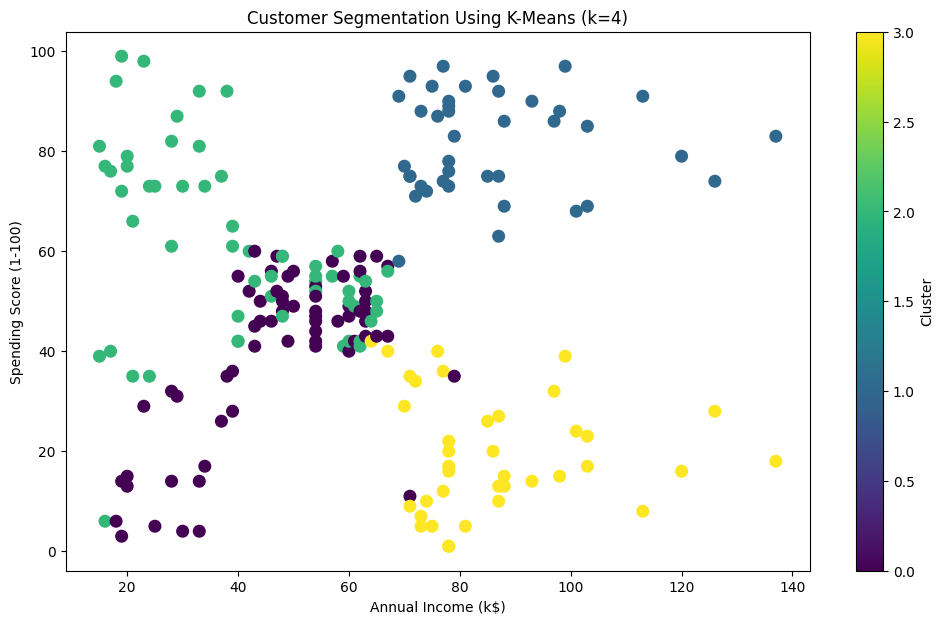

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=70
)

plt.title('Customer Segmentation Using K-Means (k=4)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(label='Cluster')

plt.show()

INFERENCE:
The Elbow Method was used to determine a suitable number of clusters for the K-Means algorithm. The inertia curve showed a **noticeable bend around k = 4**, suggesting four clusters as a reasonable choice. The final K-Means model was built using four clusters, with k-means++ initialization and ten initialisation runs to reduce sensitivity to random centroid selection. The resulting clusters can be analysed to understand customer characteristics and spending behaviour

# **Evaluating K-Means Clustering Using the Silhouette Score**
The Silhouette Score measures how well each data point fits into its assigned cluster compared with neighbouring clusters.Let's evaluate our final K-Means model using the Silhouette Score and understand whether your four customer clusters are well separated

In [ ]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled_df)

    score = silhouette_score(X_scaled_df, labels)

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

Clusters: 2, Silhouette Score: 0.3355
Clusters: 3, Silhouette Score: 0.3578
Clusters: 4, Silhouette Score: 0.4040
Clusters: 5, Silhouette Score: 0.4166
Clusters: 6, Silhouette Score: 0.4284
Clusters: 7, Silhouette Score: 0.4172
Clusters: 8, Silhouette Score: 0.4082
Clusters: 9, Silhouette Score: 0.4177
Clusters: 10, Silhouette Score: 0.4066


### **Conclusion: Six clusters produce the best Silhouette Score among the nine cluster counts you tested**
The Elbow Method focuses on how much the within-cluster variation decreases when additional clusters are introduced
Lets Compare four clusters against six clusters

Lets run the following code to create both models and compare their inertia and Silhouette Scores

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [4, 6]:

    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled_df)

    silhouette = silhouette_score(X_scaled_df, labels)

    print(f"\nNumber of clusters: {k}")
    print(f"Inertia: {model.inertia_:.4f}")
    print(f"Silhouette Score: {silhouette:.4f}")


Number of clusters: 4
Inertia: 205.2251
Silhouette Score: 0.4040

Number of clusters: 6
Inertia: 133.8684
Silhouette Score: 0.4284


Inertia

Four clusters: 205.2251
Six clusters: 133.8684

Six clusters have lower inertia, meaning customers are, overall, closer to their assigned cluster centres.

However, inertia generally decreases as the number of clusters increases, so lower inertia alone does not establish that six clusters are optimal.

Silhouette Score

Four clusters: 0.4040
Six clusters: 0.4284

Six clusters have a higher Silhouette Score, indicating better-defined clusters according to this metric.

The improvement is 0.0244.

 Lets finalise six clusters as our leading candidate, because it has the highest Silhouette Score among the cluster counts we tested

### Building final K-Means model with six clusters

In [ ]:
from sklearn.cluster import KMeans

# Create the final K-Means model
final_kmeans = KMeans(
    n_clusters=6,
    init='k-means++',
    n_init=10,
    random_state=42
)

# Fit the model
final_kmeans.fit(X_scaled_df)

# Assign cluster labels to the original dataset
df['Cluster'] = final_kmeans.labels_

# Display the first five rows
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,5
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5


In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,45
1,39
2,33
3,39
4,23
5,21


In [ ]:
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

display(cluster_summary)

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


Visualizing the six customer segments

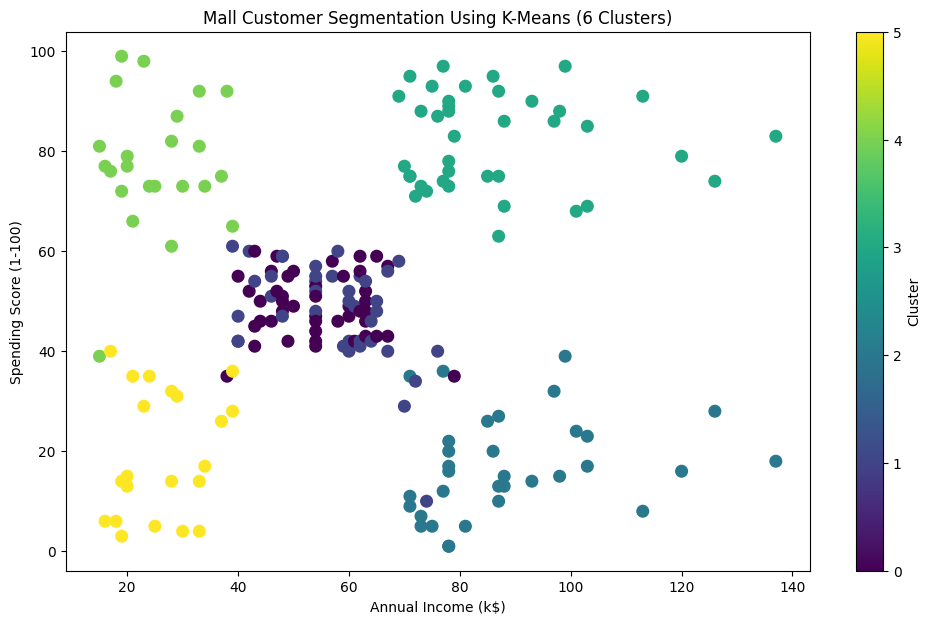

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=70
)

plt.title('Mall Customer Segmentation Using K-Means (6 Clusters)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(label='Cluster')

plt.show()

K-Means clustering was applied to the mall customer dataset using Age, Annual Income, and Spending Score as features. The Silhouette Score was evaluated for different cluster counts, and six clusters achieved the highest score of 0.4284 among the tested alternatives. The final clusters revealed different customer profiles, including high-income high-spending customers, high-income low-spending customers, low-income high-spending customers, and low-income low-spending customers. These segments can help the mall develop targeted marketing strategies, personalized offers, and customer engagement programmes

## **Task 3 – Hierarchical Clustering**
Hierarchical clustering is an unsupervised machine learning algorithm that groups similar data points into clusters by building a hierarchy of relationships

● Generate a Dendrogram
A dendrogram is a tree-like diagram that shows how individual customers or clusters are progressively merged

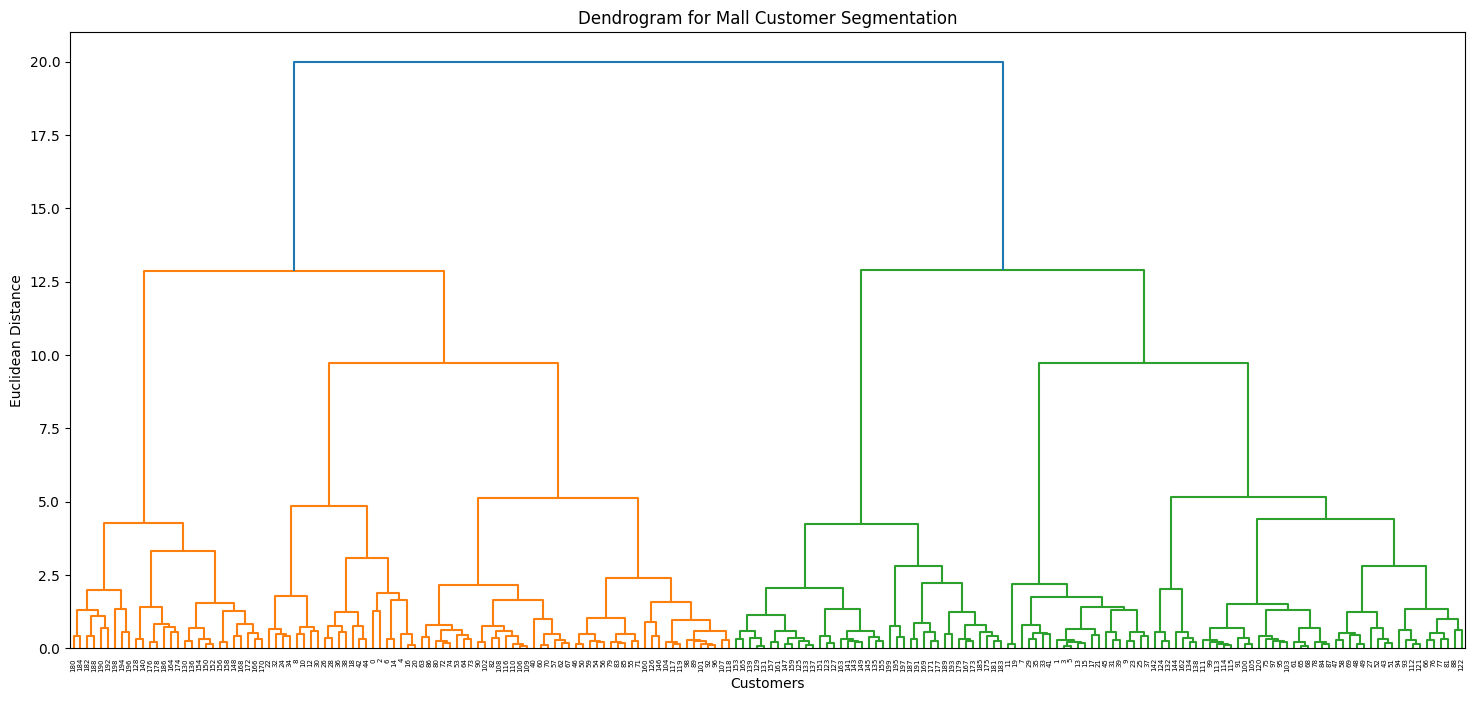

In [ ]:
plt.figure(figsize=(18, 8))

dendrogram = sch.dendrogram(
    sch.linkage(X_scaled_df, method='ward')
)

plt.title('Dendrogram for Mall Customer Segmentation')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')

plt.show()

# **Agglomerative Hierarchical Clustering**

In [ ]:
hc_model = AgglomerativeClustering(
    n_clusters=6,
    linkage='ward'
)

In [ ]:
hc_labels = hc_model.fit_predict(X_scaled_df)

In [ ]:
df['Hierarchical_Cluster'] = hc_labels

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster,Hierarchical_Cluster
0,1,Male,19,15,39,4,4
1,2,Male,21,15,81,4,5
2,3,Female,20,16,6,5,4
3,4,Female,23,16,77,4,5
4,5,Female,31,17,40,5,4


In [ ]:
df['Hierarchical_Cluster'].value_counts().sort_index()

,count
Hierarchical_Cluster,
0,45
1,45
2,39
3,28
4,22
5,21


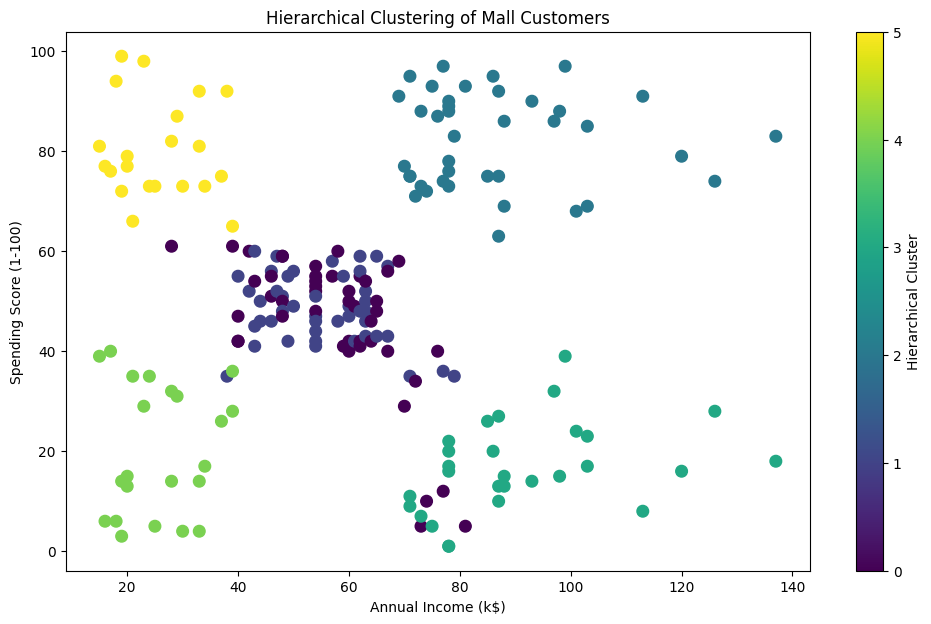

In [ ]:
plt.figure(figsize=(12, 7))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Hierarchical_Cluster'],
    cmap='viridis',
    s=70
)

plt.title('Hierarchical Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(label='Hierarchical Cluster')

plt.show()

# Comparing Hierarchical Clustering with K-Means

In [ ]:
from sklearn.metrics import silhouette_score

kmeans_silhouette = silhouette_score(
    X_scaled_df,
    df['Cluster']
)

hierarchical_silhouette = silhouette_score(
    X_scaled_df,
    df['Hierarchical_Cluster']
)

print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))

print(
    "Hierarchical Clustering Silhouette Score:",
    round(hierarchical_silhouette, 4)
)

K-Means Silhouette Score: 0.4284
Hierarchical Clustering Silhouette Score: 0.4201


Comparing cluster sizes

In [ ]:
print("K-Means cluster sizes:")
print(df['Cluster'].value_counts().sort_index())

print("\nHierarchical cluster sizes:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

K-Means cluster sizes:
Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

Hierarchical cluster sizes:
Hierarchical_Cluster
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


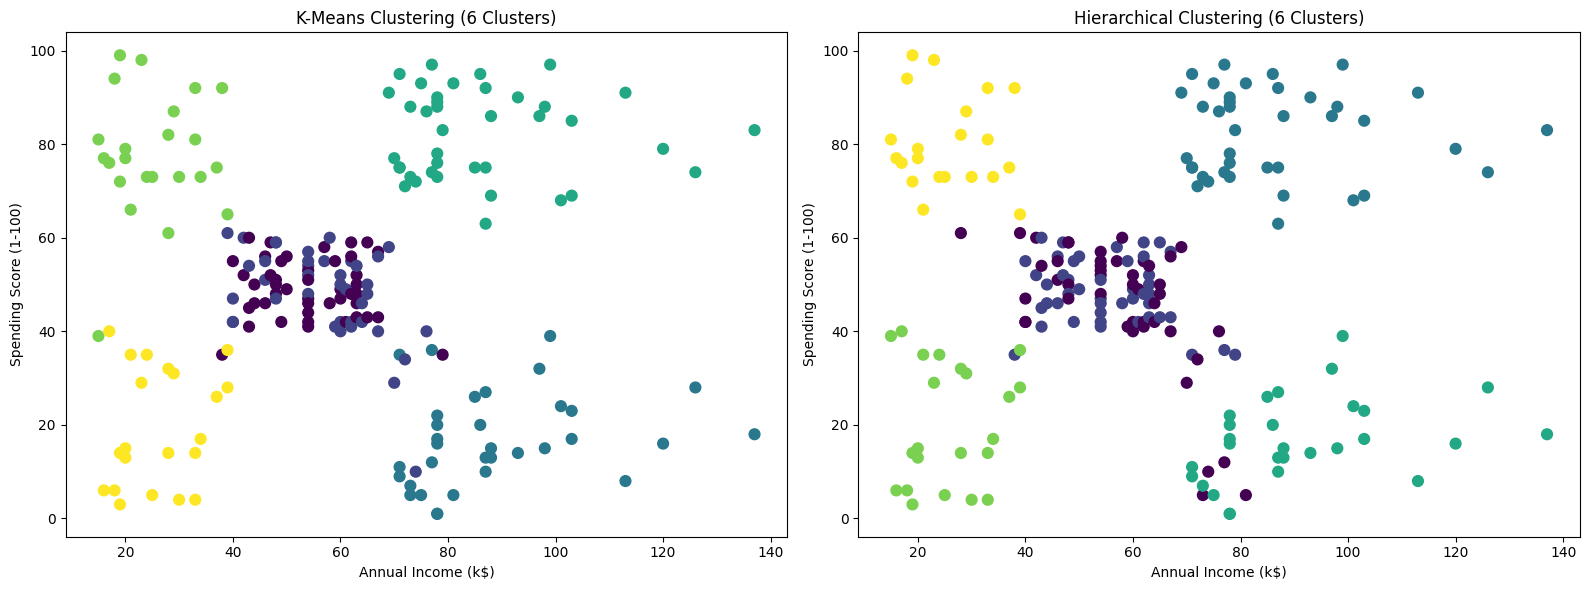

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means clusters
axes[0].scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

axes[0].set_title('K-Means Clustering (6 Clusters)')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')


# Hierarchical clusters
axes[1].scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Hierarchical_Cluster'],
    cmap='viridis',
    s=60
)

axes[1].set_title('Hierarchical Clustering (6 Clusters)')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

## **Comparison Table**

In [ ]:
comparison = pd.DataFrame({
    'Algorithm': [
        'K-Means',
        'Agglomerative Hierarchical Clustering'
    ],
    'Number of Clusters': [
        df['Cluster'].nunique(),
        df['Hierarchical_Cluster'].nunique()
    ],
    'Silhouette Score': [
        kmeans_silhouette,
        hierarchical_silhouette
    ]
})

display(comparison.round(4))

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,6,0.4284
1,Agglomerative Hierarchical Clustering,6,0.4201


K-Means and Agglomerative Hierarchical Clustering were applied to the mall customer dataset using six clusters. K-Means achieved a Silhouette Score of 0.4284, while Agglomerative Hierarchical Clustering achieved 0.4201. K-Means performed slightly better in terms of cluster separation and cohesion. However, both algorithms produced comparable results. K-Means is suitable for efficient customer segmentation, whereas Hierarchical Clustering provides a dendrogram that helps visualize the relationships between customers and understand how clusters are formed. Therefore, K-Means is the preferred model based on the Silhouette Score, although the interpretability and business relevance of the resulting customer segments should also be considered.

# Task 4 – DBSCAN Clustering
● Apply DBSCAN clustering

In [ ]:
from sklearn.cluster import DBSCAN

# Apply DBSCAN
dbscan_model = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan_model.fit_predict(X_scaled_df)

# Add cluster labels to the original dataset
df['DBSCAN_Cluster'] = dbscan_labels

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster,Hierarchical_Cluster,DBSCAN_Cluster
0,1,Male,19,15,39,4,4,-1
1,2,Male,21,15,81,4,5,0
2,3,Female,20,16,6,5,4,-1
3,4,Female,23,16,77,4,5,0
4,5,Female,31,17,40,5,4,-1


# Identify clusters and noise points

In [ ]:
cluster_counts = df['DBSCAN_Cluster'].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
DBSCAN_Cluster
-1    60
 0    17
 1     5
 2    51
 3    28
 4    32
 5     7
Name: count, dtype: int64


In [ ]:
# Number of clusters, excluding noise (-1)
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

# Number of noise points
n_noise = list(dbscan_labels).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Percentage of noise points:", round(n_noise / len(df) * 100, 2), "%")

Number of clusters: 6
Number of noise points: 60
Percentage of noise points: 30.0 %


Visualize the DBSCAN clusters

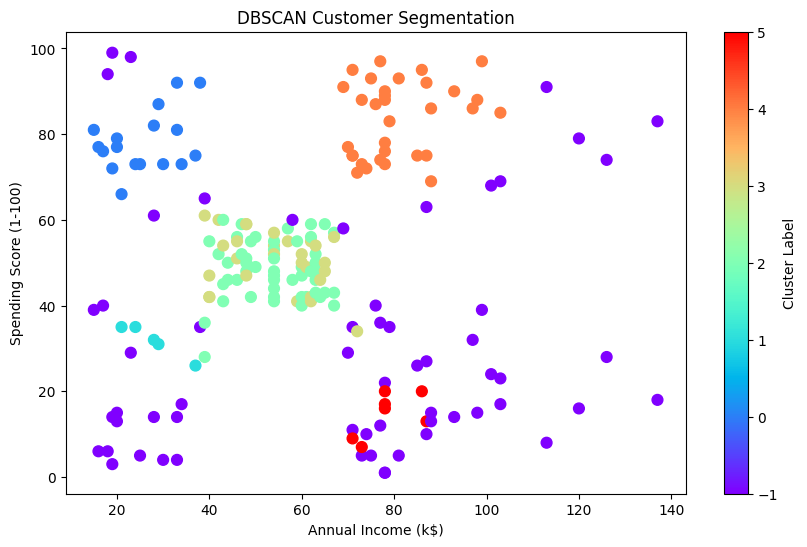

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['DBSCAN_Cluster'],
    cmap='rainbow',
    s=60
)

plt.title('DBSCAN Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.colorbar(label='Cluster Label')
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled_df)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    print(
        f"eps={eps:.1f} | "
        f"Clusters={n_clusters} | "
        f"Noise points={n_noise}"
    )

eps=0.3 | Clusters=10 | Noise points=134
eps=0.4 | Clusters=6 | Noise points=98
eps=0.5 | Clusters=6 | Noise points=60
eps=0.6 | Clusters=2 | Noise points=28
eps=0.7 | Clusters=1 | Noise points=14
eps=0.8 | Clusters=1 | Noise points=6
eps=1.0 | Clusters=1 | Noise points=2


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled_df)

    # Exclude noise points
    mask = labels != -1

    clustered_data = X_scaled_df.loc[mask]
    clustered_labels = labels[mask]

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()

    # Calculate silhouette only if at least two clusters remain
    if 2 <= len(set(clustered_labels)) < len(clustered_data):
        score = silhouette_score(
            clustered_data,
            clustered_labels
        )
    else:
        score = None

    results.append({
        'eps': eps,
        'Number of Clusters': n_clusters,
        'Noise Points': n_noise,
        'Noise Percentage': round(n_noise / len(labels) * 100, 2),
        'Silhouette Score': round(score, 4) if score is not None else None
    })

dbscan_results = pd.DataFrame(results)

print(dbscan_results)

   eps  Number of Clusters  Noise Points  Noise Percentage  Silhouette Score
0  0.3                  10           134              67.0            0.5144
1  0.4                   6            98              49.0            0.5190
2  0.5                   6            60              30.0            0.4817
3  0.6                   2            28              14.0            0.2730
4  0.7                   1            14               7.0               NaN
5  0.8                   1             6               3.0               NaN
6  1.0                   1             2               1.0               NaN


In [ ]:
# Apply the selected DBSCAN configuration
from sklearn.cluster import DBSCAN

dbscan_model = DBSCAN(eps=0.5, min_samples=5)

df['DBSCAN_Cluster'] = dbscan_model.fit_predict(X_scaled_df)

# Count customers in each cluster, including noise
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1    60
 0    17
 1     5
 2    51
 3    28
 4    32
 5     7
Name: count, dtype: int64


## **Compare DBSCAN results with K-Means and Hierarchical Clustering**

The performance of K-Means, Hierarchical Clustering, and DBSCAN was compared using the Mall Customers dataset containing 200 records. K-Means and Hierarchical Clustering both generated six clusters, achieving silhouette scores of 0.4284 and 0.4201, respectively. DBSCAN, with eps=0.5 and min_samples=5, also identified six clusters but classified 60 customers (30%) as noise. Its silhouette score was 0.4817 when calculated on the non-noise customers only. However, this score is not directly comparable with those of K-Means and Hierarchical Clustering because it excludes noise points. K-Means is suitable for segmenting all customers into predefined groups, Hierarchical Clustering helps visualize customer relationships through a dendrogram, and DBSCAN identifies dense groups while detecting potential noise points. Overall, the choice of algorithm depends on the business objective and the desired balance between cluster quality and the number of customers assigned to meaningful segment

For a fairer comparison, calculate the silhouette score for all three algorithms on the same 200 customers, if the comparison is intended to evaluate the complete clustering assignments. DBSCAN's noise label -1 should not automatically be treated as an ordinary cluster, though, because noise points do not form a genuine cluster. You can report the DBSCAN silhouette score separately for non-noise customers and clearly state how it was calculated.

# **Task 5 – Dimensionality Reduction**
● Apply PCA to reduce dimensionality

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled_df)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=X_scaled_df.index
)

pca_df.head()

,PC1,PC2
0,-0.615720,-1.763481
1,-1.665793,-1.820747
2,0.337862,-1.674799
3,-1.456573,-1.772430
4,-0.038465,-1.662740


In [ ]:
explained_variance = pca.explained_variance_ratio_

print("PC1 Explained Variance:", explained_variance[0])
print("PC2 Explained Variance:", explained_variance[1])

print("Total Explained Variance:", explained_variance.sum())

PC1 Explained Variance: 0.4426616720824504
PC2 Explained Variance: 0.33308378461522425
Total Explained Variance: 0.7757454566976747


In [ ]:
print(f"PC1: {explained_variance[0] * 100:.2f}%")
print(f"PC2: {explained_variance[1] * 100:.2f}%")

print(f"Total: {explained_variance.sum() * 100:.2f}%")

PC1: 44.27%
PC2: 33.31%
Total: 77.57%


Principal Component Analysis (PCA) was applied to reduce the dimensionality of the Mall Customers dataset from three numerical features to two principal components. The first principal component (PC1) explained 44.27% of the total variance, while the second principal component (PC2) explained 33.31%. Together, the two components retained approximately 77.57% of the total variance in the original dataset. This reduction enables two-dimensional visualization while preserving a substantial amount of information. The PCA visualization can then be used to examine the distribution and separation of the customer segments identified by K-Means clustering

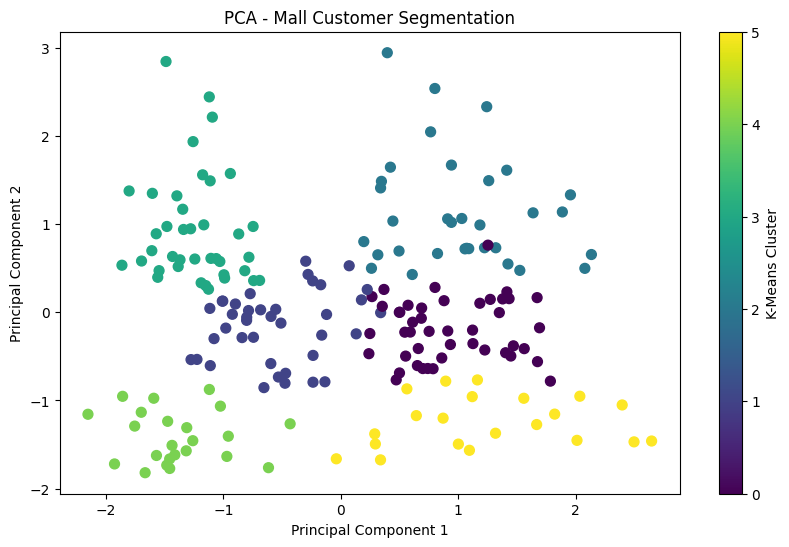

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.title('PCA - Mall Customer Segmentation')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='K-Means Cluster')

plt.show()

Apply t-SNE for low-dimensional representation

In [ ]:
from sklearn.manifold import TSNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled_df)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=X_scaled_df.index
)

tsne_df.head()

,TSNE1,TSNE2
0,-0.699413,-5.216182
1,-6.678774,-4.357728
2,0.605962,-6.731431
3,-6.220541,-4.390894
4,0.267134,-5.244290


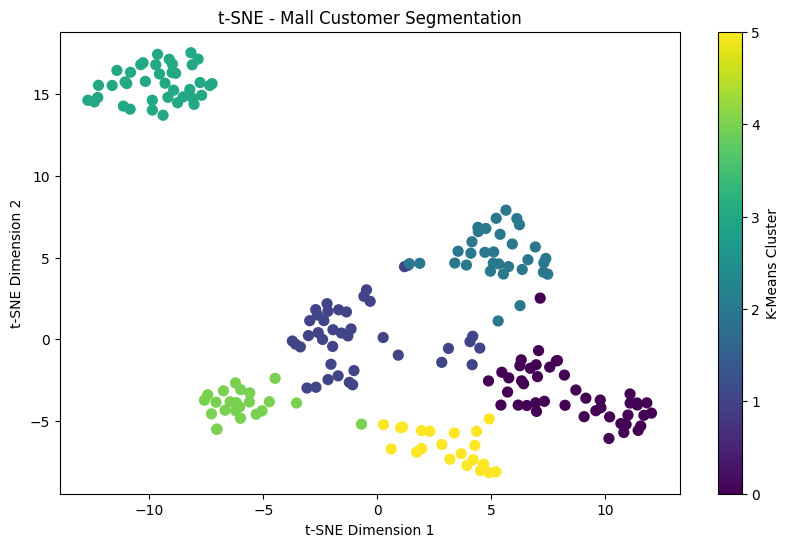

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    tsne_df['TSNE1'],
    tsne_df['TSNE2'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.title('t-SNE - Mall Customer Segmentation')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='K-Means Cluster')

plt.show()

Compare insights obtained from PCA and t-SNE
PCA and t-SNE were applied to the Mall Customers dataset to reduce dimensionality and visualize customer distribution. PCA reduced the three numerical features to two principal components, with PC1 explaining 44.27% and PC2 explaining 33.31% of the total variance. Together, these components retained approximately 77.57% of the variance in the original data. This made it possible to visualize broad patterns while preserving a substantial amount of information. In contrast, t-SNE provided a two-dimensional representation for exploring local relationships and potential groupings among customers. PCA is useful for understanding overall variation, whereas t-SNE is useful for exploring local structures in the data. Both techniques complement each other and provide different perspectives on customer segmentation

Task 6 – Cluster Analysis
● Analyze customer characteristics within each cluster
● Identify meaningful customer segments
● Provide business recommendations based on the clusters

In [ ]:
# Calculate average customer characteristics for each cluster

cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


In [ ]:
cluster_counts = df['Cluster'].value_counts().sort_index()

print(cluster_counts)

Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


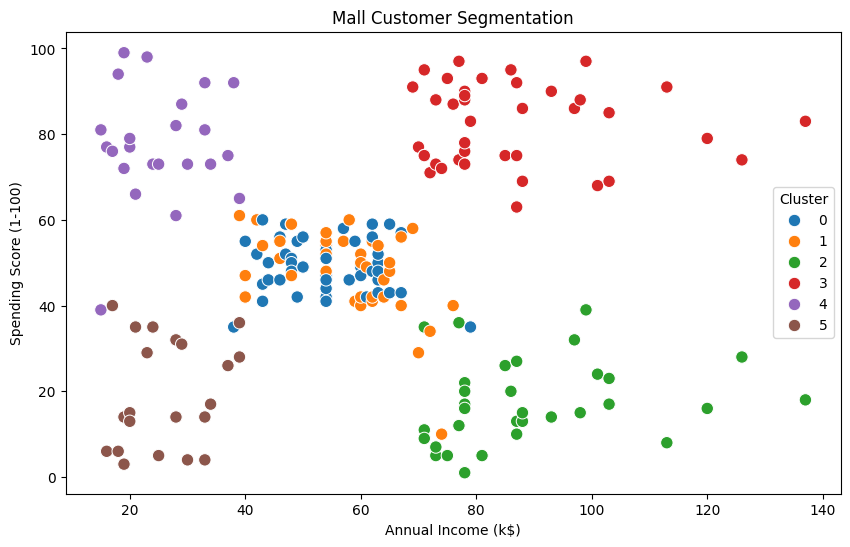

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=80
)

plt.title('Mall Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

Cluster 0: Mature, Moderate-Spending Customers
Characteristics: Average age of 56 years, moderate income, and moderate spending score.
Interpretation: These customers demonstrate moderate spending behavior and may value convenience, quality, and customer service.
Cluster 1: Young, Moderate-Spending Customers
Characteristics: Average age of 27 years, moderate income, and moderate spending score.
Interpretation: These customers may respond well to engaging promotions, seasonal offers, and loyalty rewards.
Cluster 2: High-Income, Low-Spending Customers
Characteristics: Average annual income of approximately $88,940 and a low spending score of 16.97.
Interpretation: Despite their relatively high income, these customers have low spending scores. Understanding their preferences and purchasing barriers could reveal opportunities for targeted marketing.
Cluster 3: High-Income, High-Spending Customers
Characteristics: Average annual income of approximately $86,540 and a high spending score of 82.13.
Interpretation: These customers combine high income with high spending scores, making them a potentially valuable segment for customer retention and premium marketing.
Cluster 4: Young, High-Spending Customers
Characteristics: Average age of 25 years, relatively low income, and a high spending score of 77.61.
Interpretation: These customers demonstrate high spending scores despite their lower average income. Affordable, trendy products and attractive offers may appeal to this group.
Cluster 5: Budget-Conscious, Low-Spending Customers
Characteristics: Average age of 46 years, relatively low income, and a low spending score of 19.38.
Interpretation: These customers have lower average income and spending scores. Value-for-money products and carefully targeted promotions may be appropriate.

# **Provide business recommendations based on the clusters**

1. Customer retention: Cluster 3 has both high income and high spending scores. The business could prioritize loyalty programs and personalized experiences for these customers.

2. Growth opportunities: Cluster 2 has high income but low spending scores. Targeted campaigns and further investigation into customer preferences may help identify ways to increase engagement.

3. Targeted marketing: Clusters 1, 4, and 5 have different combinations of income and spending behavior. Tailoring promotions to each segment can help the business use its marketing budget more effectively.

Important observation: Cluster 0 is your largest segment, with 45 customers (22.5% of the dataset), while Cluster 5 is your smallest, with 21 customers (10.5%). Cluster 0 may therefore deserve attention when planning broad customer-retention campaigns, while Cluster 3 may be a priority for high-value customer-retention strategies. Actual revenue and profitability data would be needed to confirm which segment contributes the most business value